# Vorwärtstransformation des Roboters (symbolisch)

Konvention: **Standard-DH**

$$
{}^{i-1}T_i = R_z(\theta_i)\,T_z(d_i)\,T_x(a_i)\,R_x(\alpha_i)
$$

Aufbau des Notebooks:
1. Imports und Hilfsfunktion `dh_matrix`
2. Gelenkvariablen und Startkonfiguration
3. Parameter der Gelenke und feste Transformationen
4. Gesamttransformation (symbolisch)
5. Auswertung (Startkonfiguration, beliebige Winkel)

## 1. Imports und Hilfsfunktion

In [1]:
import sympy as sp

sp.init_printing(use_unicode=True)


def dh_matrix(theta, d, a, alpha):
    """
    Symbolische DH-Matrix (Standard-DH).
    theta : Gelenkwinkel um z_{i-1}  [rad]  (Zahl oder sympy-Symbol)
    d     : Verschiebung entlang z_{i-1}  [Laengeneinheit]
    a     : Verschiebung entlang x_i  [Laengeneinheit]
    alpha : Verdrehung um x_i  [rad]
    """
    ct, st = sp.cos(theta), sp.sin(theta)
    ca, sa = sp.cos(alpha), sp.sin(alpha)
    return sp.Matrix([
        [ct, -st * ca,  st * sa, a * ct],
        [st,  ct * ca, -ct * sa, a * st],
        [0,        sa,       ca,      d],
        [0,         0,        0,      1],
    ])

In [2]:
def trans_matrix(vec):
    """
    Homogene 4x4-Translationsmatrix (reine Verschiebung).
    vec : Translationsvektor (x, y, z) als Liste, Tupel, sympy-Vektor oder numpy-Array
          (Zahlen oder sympy-Symbole) [Laengeneinheit]
    """
    x, y, z = vec
    return sp.Matrix([
        [1, 0, 0, x],
        [0, 1, 0, y],
        [0, 0, 1, z],
        [0, 0, 0, 1],
    ])

## 2. Gelenkvariablen und Startkonfiguration

In [63]:
# Gelenkvariablen
theta1, theta2, theta3, theta4 = sp.symbols("theta1 theta2 theta3 theta4", real=True)

# Startkonfiguration des Roboters (in Creo asm festgelegt)
start_config = {
    theta1: sp.rad(0),
    theta2: sp.rad(0),
    theta3: sp.rad(0),
}

## 3. Gelenkparameter und feste Transformationen

### World zu CS_DH0

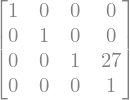

In [49]:
TW_0 = trans_matrix((0, 0, 27))
TW_0

### Gelenk 1 (CS_DH0 zu CS_DH1)

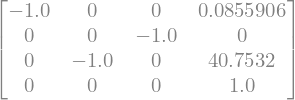

In [83]:
trans_1 = trans_matrix((0.0855906, 0, 0))

theta1_start = sp.rad(180)
d1     = 40.7532
a1     = 0
alpha1 = sp.rad(-90)   # [rad]
dh1 = dh_matrix(theta1_start + theta1, d1, a1, alpha1)

T0_1 = trans_1 @ dh1  
T0_1
T0_1.subs(start_config).evalf(8)

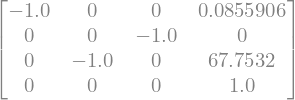

In [98]:
(TW_0 @ T0_1).subs(start_config).evalf(8)

### Gelenk 2 (CS_DH1 zu CS_DH2)

In [128]:
theta2_start = sp.rad(90)
d2     = 0
a2     = -100
alpha2 = sp.rad(0)   # [rad]
dh2 = dh_matrix(theta2_start + theta2, d2, a2, alpha2)
T1_2 = dh2

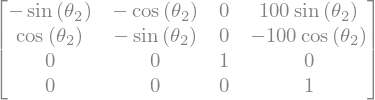

In [129]:
dh2

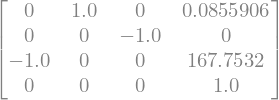

In [130]:
(TW_0 @ T0_1 @ T1_2).subs(start_config).evalf(8)

### Gelenk 3 (CS_DH2 zu CS_DH3)

In [131]:
theta3_start = sp.rad(90)
d3     = 0
a3     = 100
alpha3 = sp.rad(0)   # [rad]
dh3 = dh_matrix(theta3_start + theta3, d3, a3, alpha3)
T2_3 = dh3

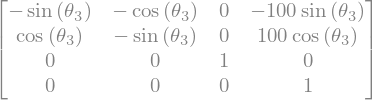

In [132]:
dh3

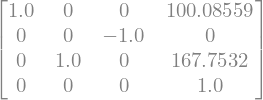

In [133]:
(TW_0 @ T0_1 @ T1_2 @ T2_3).subs(start_config).evalf(8)

### Gelenk 4 (CS_DH3 zu CS_TCP)

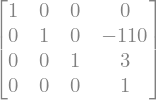

In [147]:
trans_4 = trans_matrix((0, -110, 3)) # letztes Gelenk zu TCP
trans_4

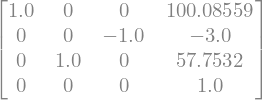

In [154]:
(TW_0 @ T0_1 @ T1_2 @ T2_3 @ trans_4).subs(start_config).evalf(8)

## 4. Gesamttransformation 

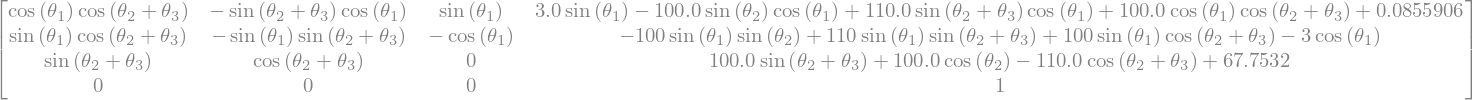

In [149]:
T = (TW_0 @ T0_1 @ T1_2 @ T2_3 @ trans_4).applyfunc(sp.trigsimp)
T

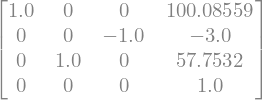

In [150]:
T.subs(start_config).evalf(8)

## 5. Auswertung

### Numerische Funktion für beliebige Gelenkwinkel (Radiant)

In [151]:
T_func = sp.lambdify((theta1, theta2, theta3, theta4), T, "numpy")

def T_num(q1, q2, q3, q4):
    """Gesamttransformation als numpy-Array fuer Gelenkwinkel in Radiant."""
    return T_func(q1, q2, q3, q4)

### Beliebige Konfiguration testen

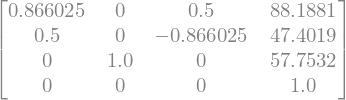

In [155]:
T_beispiel = T.subs({theta1: sp.rad(30), theta2: sp.rad(0),
                     theta3: sp.rad(0)})
T_beispiel.evalf(6)